# HOMEWORK 4

In [118]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import roc_auc_score
from sklearn.metrics import f1_score
import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score, precision_recall_curve
from sklearn.model_selection import train_test_split
from sklearn.datasets import make_classification
from sklearn.model_selection import KFold

In [119]:
df=pd.read_csv('https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv')

In [120]:
#loading dataframe
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


## Data praparation 

In [121]:
# Check if the missing values are presented in the features.
df.isna().any()

lead_source                  True
industry                     True
employment_status            True
location                     True
annual_income                True
number_of_courses_viewed    False
interaction_count           False
lead_score                   True
converted                   False
dtype: bool

In [122]:
#If there are missing values:
  #For categorical features, replace them with 'NA'
categorical_cols = ['lead_source', 'industry', 'employment_status', 'location']
df[categorical_cols] = df[categorical_cols].fillna('NA')

  #For numerical features, replace with with 0.0
numerical_cols = ['annual_income', 'lead_score','number_of_courses_viewed','interaction_count']
df[numerical_cols] = df[numerical_cols].fillna(0.0)

In [123]:
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NA,0.0,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


## Split data 

In [124]:
# Split the data into 3 parts with these exact calls:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [125]:
#Make sure that the target value converted is not in your dataframe.
    # Extract target values
y_train = df_train['converted'].values
y_val = df_val['converted'].values
y_test = df_test['converted'].values

    # Remove the target from features
df_train = df_train.drop(columns=['converted'])
df_val = df_val.drop(columns=['converted'])
df_test = df_test.drop(columns=['converted'])

In [126]:
#Question1: Which numerical variable (among the following 4) has the highest AUC?
for num in numerical_cols:
    auc_value = roc_auc_score(y_train, df_train[num])

    if auc_value < 0.5:
        auc_value = roc_auc_score(y_train, -df_train[num])

    print(f"{num}: {auc_value:.4f}")
    

annual_income: 0.6082
lead_score: 0.7882
number_of_courses_viewed: 0.7230
interaction_count: 0.7649


In [127]:
#Question 2:What's the AUC of this model on the validation dataset? (round to 3 digits)
#Apply one-hot-encoding using DictVectorizer and train the logistic regression with these parameters:
train_dicts = df_train.to_dict(orient='records')
val_dicts = df_val.to_dict(orient='records')
dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

#model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)
# Predict probabilities on validation dataset
y_val_pred = model.predict_proba(X_val)[:, 1]

#the AUC on val dataset 
auc_value = roc_auc_score(y_val,y_val_pred)

print(f"Validation AUC: {auc_value:.3f}")

Validation AUC: 0.732


In [128]:
#Question 3:At which threshold precision and recall curves intersect?
#Ignore thresholds at which both metrics are zero, and choose the threshold with the smallest absolute difference between precision and recall.
from sklearn.metrics import precision_score, recall_score

# Create thresholds from 0 to 1 with step 0.01
thresholds = np.arange(0.0, 1.01, 0.01)
precisions = []
recalls = []

for t in thresholds:
    # Convert probabilities into binary predictions
    y_pred = (y_val_pred >= t).astype(int)

    # Calculate precision and recall
    p = precision_score(y_val, y_pred, zero_division=0)
    r = recall_score(y_val, y_pred, zero_division=0)
    precisions.append(p)
    recalls.append(r)
# Calculate absolute difference
differences = np.abs(np.array(precisions) - np.array(recalls))
# Ignore thresholds where both metrics are zero
valid = (np.array(precisions) != 0) | (np.array(recalls) != 0)

# Find the threshold with the smallest difference
best_index = np.argmin(np.where(valid, differences, np.inf))

# Print results
print(f"Best threshold: {thresholds[best_index]:.2f}")
print(f"Precision: {precisions[best_index]:.3f}")
print(f"Recall: {recalls[best_index]:.3f}")



Best threshold: 0.63
Precision: 0.733
Recall: 0.725


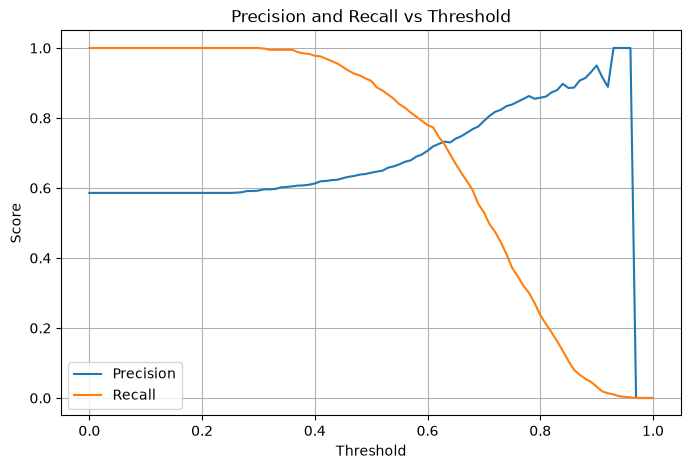

In [129]:
#Plot them 
plt.figure(figsize=(8, 5))
plt.plot(thresholds, precisions, label='Precision')
plt.plot(thresholds, recalls, label='Recall')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Precision and Recall vs Threshold')
plt.legend()
plt.grid()
plt.show()


In [130]:
#Question4: At which threshold F1 is maximal?

thresholds = np.arange(0.0, 1.0, 0.01)

f1_scores = []

for t in thresholds:
    # Convert probabilities into binary predictions
    y_pred = (y_val_pred >= t).astype(int)

    # Calculate F1-score
    f1 = f1_score(y_val, y_pred, zero_division=0)

    f1_scores.append(f1)

# Find threshold with maximum F1-score
best_index = np.argmax(f1_scores)
best_threshold = thresholds[best_index]
best_f1 = f1_scores[best_index]
print(f"Best threshold: {best_threshold:.2f}")
print(f"Maximum F1-score: {best_f1:.4f}")

Best threshold: 0.41
Maximum F1-score: 0.7576


In [131]:
#Question5: from sklearn.model_selection import KFold
# Create 5 folds
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

scores = []

for train_idx, val_idx in kfold.split(df_full_train):

    # Split data into training and validation
    df_train_fold = df_full_train.iloc[train_idx].copy()
    df_val_fold = df_full_train.iloc[val_idx].copy()

    # Extract target values
    y_train_fold = df_train_fold.pop('converted').values
    y_val_fold = df_val_fold.pop('converted').values

    # One-hot encoding
    dv = DictVectorizer(sparse=False)
    X_train_fold = dv.fit_transform( df_train_fold.to_dict(orient='records'))
    X_val_fold = dv.transform(df_val_fold.to_dict(orient='records'))

    # Train logistic regression
    model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000 )
    model.fit(X_train_fold, y_train_fold)

    # Predict probabilities
    y_pred = model.predict_proba(X_val_fold)[:, 1]

    # Calculate ROC AUC
    auc = roc_auc_score(y_val_fold, y_pred)

    scores.append(auc)

# Display results
print("AUC scores:", scores)
print(f"Mean AUC: {np.mean(scores):.3f}")
print(f"Standard deviation: {np.std(scores):.3f}")


AUC scores: [0.7305601027122453, 0.7295726148196622, 0.7363428071259397, 0.7412454717957564, 0.7209138590326581]
Mean AUC: 0.732
Standard deviation: 0.007


In [132]:
# Question6: Which C leads to the best mean ROC AUC?

C_values = [0.000001, 0.001, 1]

kfold = KFold(n_splits=5, shuffle=True, random_state=1)

scores = {}

for c in C_values:

    roc_auc_scores = []

    for train_idx, val_idx in kfold.split(df_full_train):

        # Split training and validation data
        df_train_fold = df_full_train.iloc[train_idx].copy()
        df_val_fold = df_full_train.iloc[val_idx].copy()

        # Extract target
        y_train_fold = df_train_fold.pop('converted').values
        y_val_fold = df_val_fold.pop('converted').values

        # One-hot encoding
        dv = DictVectorizer(sparse=False)

        X_train_fold = dv.fit_transform(df_train_fold.to_dict(orient='records'))
        X_val_fold = dv.transform(df_val_fold.to_dict(orient='records'))

        # Train model with parameter C
        model = LogisticRegression(solver='liblinear',C=c,max_iter=1000)
        model.fit(X_train_fold, y_train_fold)

        # Predict probabilities
        y_pred = model.predict_proba(X_val_fold)[:, 1]

        # Calculate ROC AUC
        auc = roc_auc_score(y_val_fold, y_pred)

        roc_auc_scores.append(auc)

    # Calculate mean and standard deviation(second for)
    mean_roc_auc = round(np.mean(roc_auc_scores), 3)
    std_roc_auc = round(np.std(roc_auc_scores), 3)

    scores[c] = (mean_roc_auc, std_roc_auc)

    print(f"C = {c:g}")
    print(f"Mean ROC AUC: {mean_roc_auc:.3f}")
    print(f"Std ROC AUC: {std_roc_auc:.3f}")
    print("--------------------")

# Best C: highest mean, then lowest std, then smallest C
best_c = sorted(C_values,key=lambda c: (-scores[c][0], scores[c][1], c))[0]
print("Best C:", best_c)
print("Best mean ROC AUC:", scores[best_c][0])

C = 1e-06
Mean ROC AUC: 0.617
Std ROC AUC: 0.019
--------------------
C = 0.001
Mean ROC AUC: 0.749
Std ROC AUC: 0.010
--------------------
C = 1
Mean ROC AUC: 0.732
Std ROC AUC: 0.007
--------------------
Best C: 0.001
Best mean ROC AUC: 0.749
